# SMILES token-length EDA for decoder sizing

> **Historical supplied-target analysis:** The generator now uses
> `casmi_generative_ranker/molecular_preprocessing.py` to create competition-normalized
> targets and three identity-disjoint partitions. The saved results below use the
> original supplied strings and 80/20 EDA split. Refit the tokenizer and rerun length
> EDA on the new targets and exact training partition before choosing a model limit.

Scan the full training parquet using **only `inchikey14` and `normalized_smiles`**. Each supplied molecule identity contributes once; repeated spectra do not affect the curves. No length filter or truncation is applied.

The default **NEW hash-grouped 80/20 EDA split** matches the seed and identity assignment in `peak_retention_eda.ipynb`. This is not the generator pipeline’s three-way split. Supply `SPLIT_LOOKUP` to reuse an existing molecule split before length filtering. Already-filtered training artifacts would hide the tail.

Use the pipeline’s BPE tokenizer family and 512-token vocabulary, fitted only on valid training representatives. Lengths include **one BOS and one EOS**. Invalid/missing SMILES stay in the audit and invalid-rate denominator, but are excluded from token statistics. Unknown-token percentages exclude BOS/EOS from their denominator; molecule-level unknown rates are also reported.

In [1]:
import importlib.util
import subprocess
import sys
packages = ('pyarrow', 'numpy', 'pandas', 'matplotlib', 'rdkit', 'tokenizers')
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
try:
    import google.colab
except ImportError:
    pass
else:
    from google.colab import drive
    drive.mount('/content/drive')

In [2]:
from pathlib import Path
# Works from the workspace root, repository root, eda directory, or Colab.
local_candidates = [parent / 'enveda-CASMI26-molecule-id-mass-spectra/train.parquet'
                    for parent in (Path.cwd(), *Path.cwd().parents)]
TRAIN_PATH = next((p for p in local_candidates if p.is_file()),
                  Path('/content/drive/MyDrive/Colab Notebooks/train.parquet'))
eda_candidates = (Path.cwd() / 'CECS_551_Mass_Spectrometry/eda', Path.cwd() / 'eda', Path.cwd())
EDA_DIR = next((p for p in eda_candidates if (p / 'smiles_length_eda.ipynb').is_file()), TRAIN_PATH.parent)
OUTPUT_DIR = EDA_DIR / 'smiles_length_results'
KEY_COL = 'inchikey14'
SMILES_COL = 'normalized_smiles'
SEED = 42
VALIDATION_FRACTION = 0.2
VOCAB_SIZE = 512
LIMITS = (128, 160, 256, 512)  # 160 is the current pipeline default.
BATCH_SIZE = 8192
# Optional complete {identity: 'Training' or 'Validation'} dictionary.
# Use the SAME lookup as encoder EDA when comparing the same partitions.
SPLIT_LOOKUP = None
assert TRAIN_PATH.is_file(), f'Update TRAIN_PATH: {TRAIN_PATH}'
print('Input:', TRAIN_PATH)
print('Output:', OUTPUT_DIR)

Input: /Users/muddassirzafar/Library/CloudStorage/OneDrive-csulb/neural_networks/AIXBenyamin/enveda-CASMI26-molecule-id-mass-spectra/train.parquet
Output: /Users/muddassirzafar/Library/CloudStorage/OneDrive-csulb/neural_networks/AIXBenyamin/CECS_551_Mass_Spectrometry/eda/smiles_length_results


## Analysis functions

These are embedded from the companion `smiles_length_eda.py`, so this notebook also runs by itself in Colab. Memory grows with unique identity/SMILES pairs, while spectral arrays are never loaded. If one identity has multiple SMILES, choose the lexicographically smallest nonempty supplied string, and report how often this occurs. Supplied `inchikey14` groups connectivity and may collapse stereoisomers; this does not chemically restandardize identities or canonicalize strings.

In [3]:
"""Full-dataset, molecule-weighted decoder-length EDA; no spectra are loaded.

Run with --help for local usage, or use the self-contained companion notebook.
"""
import argparse
import hashlib
import importlib.metadata
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from rdkit import Chem, rdBase
from tokenizers import Tokenizer, models, processors, trainers

SPLITS = ("Training", "Validation")
SPECIAL_TOKENS = ["<pad>", "<s>", "</s>", "[UNK]"]


def split_for_key(key, validation_fraction=0.2, seed=42):
    """Identical to the existing peak-retention notebook's EDA assignment."""
    digest = hashlib.blake2b(f"{seed}:{key}".encode(), digest_size=8).digest()
    fraction = int.from_bytes(digest, "big") / 2**64
    return "Validation" if fraction < validation_fraction else "Training"


def collect_molecules(path, key_col="inchikey14", smiles_col="normalized_smiles",
                      batch_size=8192):
    """Keep one deterministic supplied SMILES per identity, without spectra.

    Prefer nonempty strings, then the lexicographically smallest representation.
    Missing/empty SMILES remain as an invalid representative if no string exists.
    Memory scales with unique identity/SMILES pairs, not spectrum-array size.
    """
    if batch_size < 1:
        raise ValueError("batch_size must be positive")
    variants = {}
    counts = Counter()
    with pq.ParquetFile(path, pre_buffer=False) as pf:
        missing = {key_col, smiles_col} - set(pf.schema_arrow.names)
        if missing:
            raise ValueError(f"Missing columns: {sorted(missing)}")
        expected = pf.metadata.num_rows
        for batch in pf.iter_batches(batch_size=batch_size,
                                     columns=[key_col, smiles_col], use_threads=False):
            keys, strings = (column.to_pylist() for column in batch.columns)
            for raw_key, raw_smiles in zip(keys, strings):
                counts["rows_scanned"] += 1
                if raw_smiles is None or not str(raw_smiles).strip():
                    counts["rows_missing_or_empty_smiles"] += 1
                key = str(raw_key).strip() if raw_key is not None else ""
                if not key or key.lower() in ("nan", "none", "null"):
                    counts["rows_missing_identity"] += 1
                    continue
                # Do not strip/normalize molecular strings before measuring them.
                values = variants.setdefault(key, set())
                if isinstance(raw_smiles, str) and raw_smiles.strip():
                    values.add(raw_smiles)
            if counts["rows_scanned"] % 500_000 < batch.num_rows:
                print(f"Scanned {counts['rows_scanned']:,} / {expected:,} rows", flush=True)
    records = [(key, min(values) if values else None, len(values))
               for key, values in sorted(variants.items())]
    if not records:
        raise ValueError("No molecules with a supplied identity were found")
    frame = pd.DataFrame(records, columns=["identity", "smiles", "n_smiles_variants"])
    # Include zero counts explicitly in the report.
    audit = {name: counts[name] for name in (
        "rows_scanned", "rows_missing_identity", "rows_missing_or_empty_smiles")}
    audit.update(unique_identities=len(frame),
                 identities_with_multiple_smiles=int((frame.n_smiles_variants > 1).sum()),
                 unique_identity_smiles_pairs=sum(map(len, variants.values())))
    return frame, audit


def validate_smiles(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return "missing_or_empty"
    try:
        # Strict parsing: whitespace/name suffixes must not be silently ignored.
        params = Chem.SmilesParserParams()
        params.parseName = False
        with rdBase.BlockLogs():
            mol = Chem.MolFromSmiles(smiles, params)
        return "valid" if mol is not None and mol.GetNumAtoms() else "invalid_smiles"
    except (ValueError, RuntimeError):
        return "invalid_smiles"


def fit_training_tokenizer(training_smiles, vocab_size=512):
    """Match pipeline.py's BPE family, vocabulary size, and BOS/EOS wrapper.

    Train only on valid, untruncated training representatives. Validation strings
    never contribute to the alphabet or merges. Sorted input makes ties stable.
    """
    strings = sorted(set(training_smiles))
    if not strings:
        raise ValueError("No valid training molecules to fit the tokenizer")
    alphabet = sorted(set("".join(strings)))
    if vocab_size < len(alphabet) + len(SPECIAL_TOKENS):
        raise ValueError("vocab_size is too small for the training alphabet and specials")
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS,
        initial_alphabet=alphabet, show_progress=False)
    tokenizer.train_from_iterator(strings, trainer=trainer)
    tokenizer.post_processor = processors.TemplateProcessing(
        single="<s> $A </s>", special_tokens=[("<s>", 1), ("</s>", 2)])
    tokenizer.no_truncation()
    tokenizer.no_padding()
    return tokenizer


def measure_molecules(frame, tokenizer, batch_size=2048):
    """Invalid representatives stay in the audit, with no token measurements."""
    frame = frame.copy()
    for column in ("token_length", "content_tokens", "unknown_tokens"):
        frame[column] = pd.Series(pd.NA, index=frame.index, dtype="Int64")
    frame["roundtrip_ok"] = pd.Series(pd.NA, index=frame.index, dtype="boolean")
    valid_indices = frame.index[frame.status == "valid"].tolist()
    unknown_id = tokenizer.token_to_id("[UNK]")
    for start in range(0, len(valid_indices), batch_size):
        indices = valid_indices[start:start + batch_size]
        strings = frame.loc[indices, "smiles"].tolist()
        encodings = tokenizer.encode_batch(strings, add_special_tokens=True)
        for index, smiles, encoding in zip(indices, strings, encodings):
            assert encoding.ids[0] == 1 and encoding.ids[-1] == 2
            frame.at[index, "token_length"] = len(encoding.ids)
            frame.at[index, "content_tokens"] = len(encoding.ids) - 2
            frame.at[index, "unknown_tokens"] = encoding.ids.count(unknown_id)
            decoded = tokenizer.decode(encoding.ids, skip_special_tokens=True).replace(" ", "")
            frame.at[index, "roundtrip_ok"] = decoded == smiles
    return frame


def summarize(frame, limits=(128, 160, 256, 512)):
    """Length/UNK denominators: valid unique identities; invalid rate: all IDs."""
    records = []
    for split in SPLITS:
        part = frame[frame.split == split]
        valid = part[part.status == "valid"]
        lengths = valid.token_length.to_numpy(dtype=np.int64)
        content = int(valid.content_tokens.sum())
        unknown = int(valid.unknown_tokens.sum())
        rec = dict(split=split, unique_molecules=len(part), valid_molecules=len(valid),
                   invalid_or_missing_molecules=int((part.status != "valid").sum()),
                   missing_smiles_molecules=int((part.status == "missing_or_empty").sum()),
                   invalid_smiles_molecules=int((part.status == "invalid_smiles").sum()),
                   invalid_or_missing_pct=100 * (part.status != "valid").mean() if len(part) else None,
                   median=float(np.median(lengths)) if len(lengths) else None,
                   p95=float(np.percentile(lengths, 95)) if len(lengths) else None,
                   p99=float(np.percentile(lengths, 99)) if len(lengths) else None,
                   maximum=int(lengths.max()) if len(lengths) else None,
                   content_tokens=content, unknown_tokens=unknown,
                   unknown_token_pct=100 * unknown / content if content else None,
                   molecules_with_unknown_pct=100 * (valid.unknown_tokens > 0).mean() if len(valid) else None,
                   roundtrip_failure_pct=100 * (~valid.roundtrip_ok).mean() if len(valid) else None)
        for limit in limits:
            rec[f"exceed_{limit}_pct"] = 100 * float((lengths > limit).mean()) if len(lengths) else None
        records.append(rec)
    return pd.DataFrame(records)


def plot_lengths(frame, limits, split_mode):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
    valid = frame[frame.status == "valid"]
    maximum = int(valid.token_length.max())
    step = max(1, int(np.ceil(maximum / 100)))
    bins = np.arange(0.5, maximum + step + 1, step)
    for split, color in zip(SPLITS, ("#2563eb", "#e66b16")):
        lengths = valid.loc[valid.split == split, "token_length"].to_numpy(dtype=np.int64)
        if not len(lengths):
            continue
        axes[0].hist(lengths, bins=bins, weights=np.full(len(lengths), 100 / len(lengths)),
                     histtype="step", linewidth=1.8, color=color, label=f"{split} (n={len(lengths):,})")
        x = np.arange(max(maximum, max(limits)) + 1)
        y = 100 * (1 - np.searchsorted(np.sort(lengths), x, side="right") / len(lengths))
        axes[1].plot(x, y, color=color, label=split)
    for i, ax in enumerate(axes):
        for limit in limits:
            if i == 1 or limit <= maximum:
                ax.axvline(limit, color="0.5", linestyle=":", alpha=0.6)
        ax.set_xlabel("SMILES tokens, including BOS + EOS")
        ax.grid(alpha=0.15)
        ax.legend()
    axes[0].set(title="Distribution of valid unique molecules", ylabel="Molecules per bin (%)",
                xlim=(0, maximum * 1.05))
    axes[1].set(title="Molecules exceeding each decoder limit", ylabel="Molecules above limit (%)",
                xlim=(0, max(maximum, max(limits)) * 1.02), ylim=(0, 100))
    axes[1].set_yscale("symlog", linthresh=0.01)
    axes[1].set_xticks(sorted(set([0, *limits])))
    axes[1].set_yticks([0, 0.1, 1, 10, 100], ["0", "0.1", "1", "10", "100"])
    fig.suptitle(f"Decoder output-length EDA | {split_mode} | training-only BPE", fontsize=12)
    return fig


def run_eda(train_path, output_dir, *, seed=42, validation_fraction=0.2,
            vocab_size=512, limits=(128, 160, 256, 512), batch_size=8192,
            key_col="inchikey14", smiles_col="normalized_smiles", split_lookup=None):
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be between zero and one")
    limits = tuple(sorted(set(int(x) for x in limits)))
    if not limits or min(limits) < 2:
        raise ValueError("Decoder limits must be >= 2, including BOS/EOS")
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    frame, scan = collect_molecules(train_path, key_col, smiles_col, batch_size)
    if split_lookup is None:
        frame["split"] = [split_for_key(key, validation_fraction, seed) for key in frame.identity]
        split_mode = "NEW hash-grouped EDA split"
    else:
        frame["split"] = frame.identity.map(split_lookup)
        if not frame.split.isin(SPLITS).all():
            raise ValueError("split_lookup must map every identity to Training or Validation")
        split_mode = "Existing supplied molecule split"
    if set(frame.split) != set(SPLITS):
        raise ValueError("Both training and validation molecules are required")
    print(f"Validating {len(frame):,} unique supplied molecule identities ...", flush=True)
    frame["status"] = frame.smiles.map(validate_smiles)
    training = frame[(frame.split == "Training") & (frame.status == "valid")]
    print(f"Fitting BPE on {len(training):,} valid training molecules only ...", flush=True)
    tokenizer = fit_training_tokenizer(training.smiles, vocab_size)
    frame = measure_molecules(frame, tokenizer)
    summary = summarize(frame, limits)
    figure = plot_lengths(frame, limits, split_mode)
    tokenizer.save(str(output / "tokenizer.json"))
    frame.to_csv(output / "smiles_molecule_lengths.csv", index=False)
    summary.to_csv(output / "smiles_length_summary.csv", index=False)
    figure.savefig(output / "smiles_token_lengths.png", dpi=170)
    report = dict(
        input_path=str(Path(train_path).resolve()), split_mode=split_mode,
        seed=seed, validation_fraction=validation_fraction, batch_size=batch_size,
        key_column=key_col, smiles_column=smiles_col, scan=scan,
        representative_policy="One supplied identity; lexicographically smallest nonempty supplied SMILES",
        identity_caveat="inchikey14 groups connectivity, including stereoisomers; supplied IDs are not chemically restandardized",
        tokenizer=dict(type="BPE", requested_vocab=vocab_size, actual_vocab=tokenizer.get_vocab_size(),
                       fit_split="Training", fit_valid_unique_smiles=int(training.smiles.nunique()),
                       special_tokens=SPECIAL_TOKENS, truncation=False, padding=False),
        length_definition="Untruncated content tokens + one BOS + one EOS, valid representatives only",
        percentile_method="NumPy linear interpolation",
        invalid_denominator="All unique supplied identities in each split, including missing SMILES",
        unknown_token_denominator="Content tokens of valid unique representatives, excluding BOS/EOS",
        exceed_definition="Strictly greater than each candidate limit; denominator = valid unique representatives",
        candidate_limits=list(limits),
        versions={name: importlib.metadata.version(name) for name in
                  ("numpy", "pandas", "pyarrow", "rdkit", "tokenizers", "matplotlib")},
        summary=json.loads(summary.to_json(orient="records")))
    (output / "smiles_scan_report.json").write_text(json.dumps(report, indent=2) + "\n")
    print(summary.to_string(index=False), flush=True)
    print(f"Saved plot, summaries, molecule audit, and training-only tokenizer to {output}")
    return figure, summary, frame, report



Scanned 507,904 / 2,539,608 rows
Scanned 1,007,616 / 2,539,608 rows
Scanned 1,507,328 / 2,539,608 rows
Scanned 2,007,040 / 2,539,608 rows
Scanned 2,506,752 / 2,539,608 rows
Validating 275,810 unique supplied molecule identities ...
Fitting BPE on 220,770 valid training molecules only ...
     split  unique_molecules  valid_molecules  invalid_or_missing_molecules  missing_smiles_molecules  invalid_smiles_molecules  invalid_or_missing_pct  median  p95  p99  maximum  content_tokens  unknown_tokens  unknown_token_pct  molecules_with_unknown_pct  roundtrip_failure_pct  exceed_128_pct  exceed_160_pct  exceed_256_pct  exceed_512_pct
  Training            220770           220770                             0                         0                         0                     0.0    11.0 18.0 30.0      105         2253115               0                0.0                         0.0                    0.0             0.0             0.0             0.0             0.0
Validation           

,split,unique_molecules,valid_molecules,invalid_or_missing_molecules,missing_smiles_molecules,invalid_smiles_molecules,invalid_or_missing_pct,median,p95,p99,maximum,content_tokens,unknown_tokens,unknown_token_pct,molecules_with_unknown_pct,roundtrip_failure_pct,exceed_128_pct,exceed_160_pct,exceed_256_pct,exceed_512_pct
0,Training,220770,220770,0,0,0,0.0,11.0,18.0,30.0,105,2253115,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Validation,55040,55040,0,0,0,0.0,11.0,18.0,30.0,107,561454,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


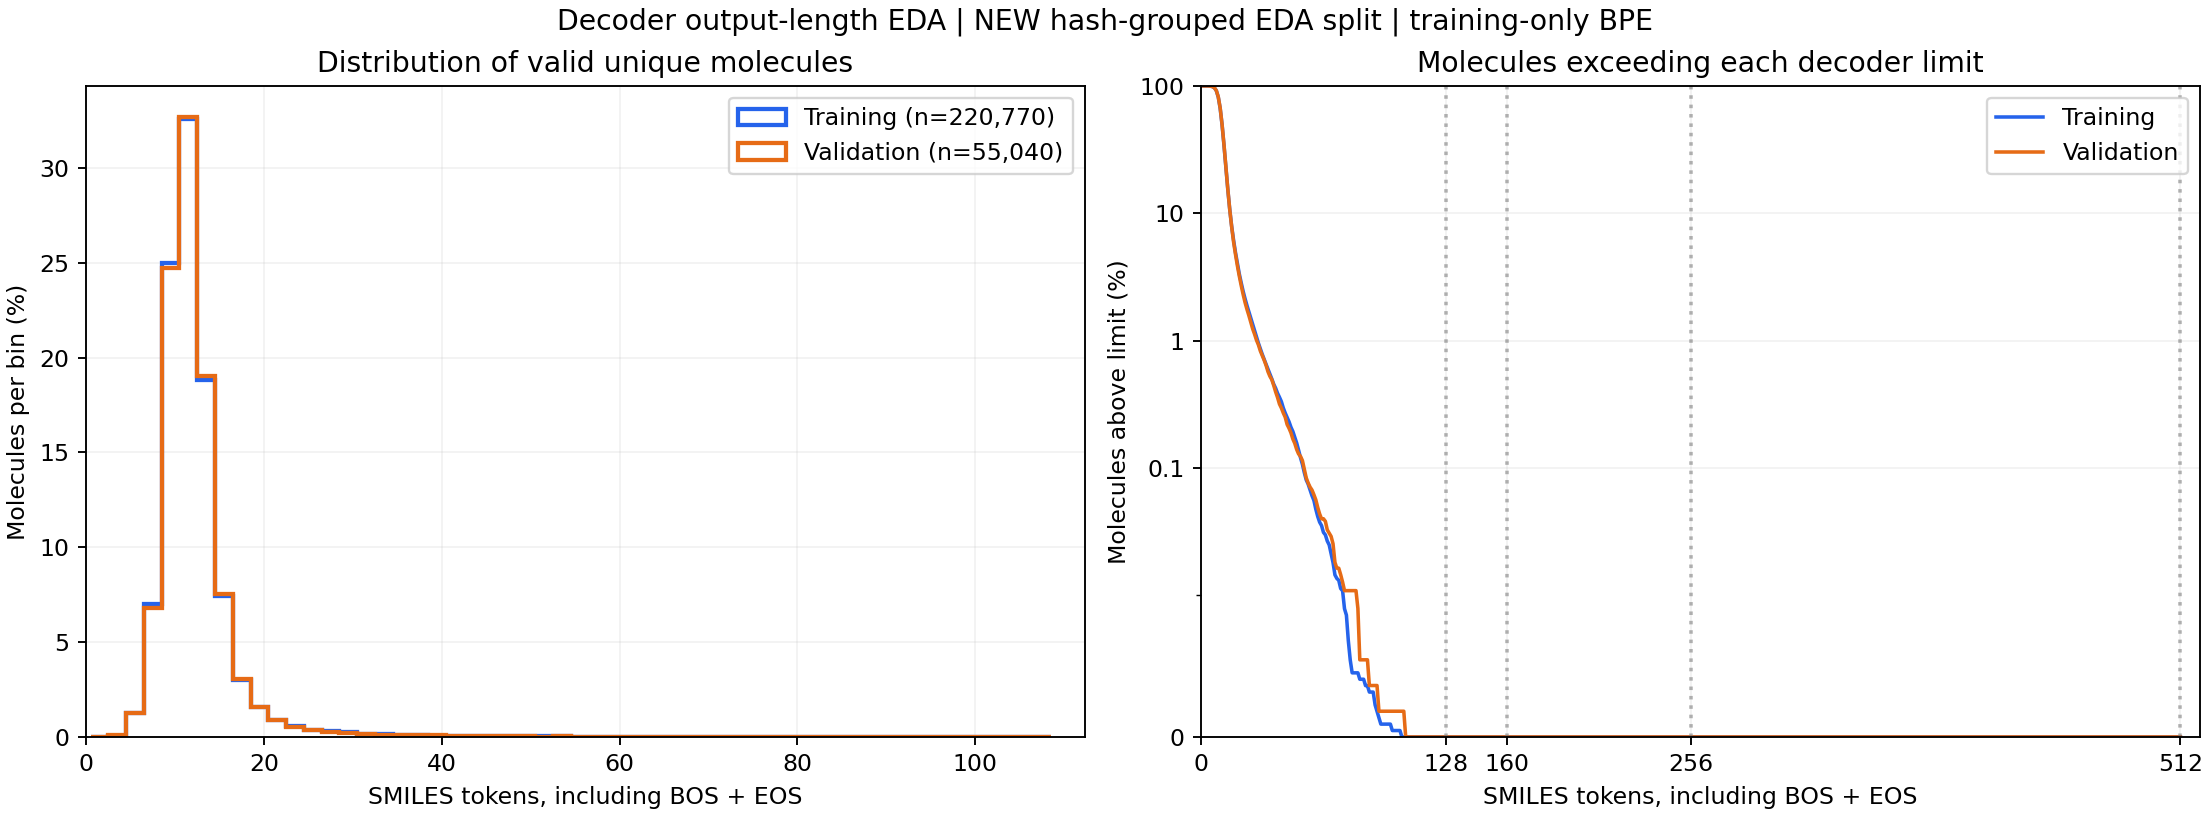

In [4]:
fig, summary, molecules, report = run_eda(
    TRAIN_PATH, OUTPUT_DIR, seed=SEED, validation_fraction=VALIDATION_FRACTION,
    vocab_size=VOCAB_SIZE, limits=LIMITS, batch_size=BATCH_SIZE,
    key_col=KEY_COL, smiles_col=SMILES_COL, split_lookup=SPLIT_LOOKUP)
from IPython.display import Image, display
import matplotlib.pyplot as plt
display(summary.round(4))
display(Image(filename=str(OUTPUT_DIR / "smiles_token_lengths.png")))
plt.close(fig)

## How to choose a limit

Compare the validation 99th percentile and exceedance percentages. A limit is a coverage/memory tradeoff, not a guarantee of chemical correctness. Validation lengths containing unknown tokens may be underestimated; fix coverage or use a suitable fallback before setting a final limit. A vocabulary or tokenizer change requires rerunning this analysis.

A decoder self-attention matrix grows roughly with the square of output length; other activations, cross-attention, batch size, and implementation also affect actual memory. Measure training memory for the chosen architecture.

Keep BOS/EOS in the chosen budget. Route or explicitly reject longer targets and count them; do not silently truncate molecular strings. Reuse the exported tokenizer only with the matching training split and vocabulary settings.

Saved outputs: `smiles_token_lengths.png`, `smiles_length_summary.csv`, `smiles_molecule_lengths.csv`, `smiles_scan_report.json`, and `tokenizer.json`. The report records denominators, configuration, package versions, missing identities, and multiple-representation counts. Percentiles use NumPy linear interpolation.